In [1]:
# import depencencies
import sys
sys.path.append("../..")

# import custom configs and utils
from data.w1_if_getHistoricalData import w1_if_getHistoricalData_M
from utils.w2_plot import w2_plotInOneScale

In [2]:
ticker_str = 'AAPL'

In [3]:
simulated_on = True

In [4]:
# download minutely data and append information
historical_data_minutely_df = w1_if_getHistoricalData_M(
    ticker_str = ticker_str,
    in_loop_on = True,
    simulated_on = simulated_on
)
historical_data_minutely_df

,date,open,high,low,close,volume
0,2026-05-11 09:30:00,291.98,292.80,291.42,292.31,1037722
1,2026-05-11 09:31:00,292.31,292.67,291.23,291.55,216790
2,2026-05-11 09:32:00,291.54,291.59,290.65,290.75,198432
3,2026-05-11 09:33:00,290.75,291.20,290.66,290.77,161616
4,2026-05-11 09:34:00,290.79,291.35,290.50,291.30,170708
...,...,...,...,...,...,...
1945,2026-05-15 15:55:00,300.23,300.66,300.23,300.58,218054
1946,2026-05-15 15:56:00,300.57,300.58,300.35,300.43,199236
1947,2026-05-15 15:57:00,300.42,300.50,300.34,300.41,242418
1948,2026-05-15 15:58:00,300.41,300.42,300.14,300.24,400187


In [5]:
historical_data_minutely_df = historical_data_minutely_df.sort_values(by = ['date']).set_index('date')
historical_data_minutely_resampled_df = historical_data_minutely_df.resample('min').first()

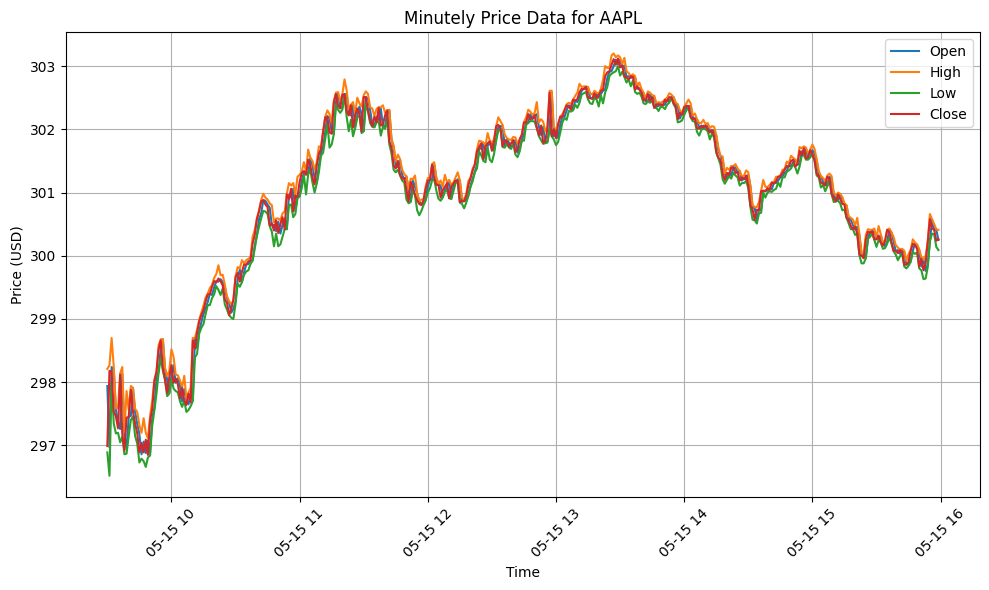

In [6]:
# plot data
w2_plotInOneScale(
    x_data_df = historical_data_minutely_resampled_df.index,
    x_axis_label_str = 'Time',
    y_data_df_list = [
        historical_data_minutely_resampled_df['open'], 
        historical_data_minutely_resampled_df['high'], 
        historical_data_minutely_resampled_df['low'], 
        historical_data_minutely_resampled_df['close']],
    y_data_label_str_list = ['Open', 'High', 'Low', 'Close'],
    y_axis_label_str = 'Price (USD)',
    plot_title_str = f'Minutely Price Data for {ticker_str}',
    recent_data_chunk_int = 1000,
    show_on = True
)

In [7]:
# # plot data
# w2_plotInOneScale(
#     x_data_df = historical_data_minutely_resampled_df.index,
#     x_axis_label_str = 'Time',
#     y_data_df_list = [
#         historical_data_minutely_resampled_df['volume']
#     ],
#     y_data_label_str_list = ['Volume'],
#     y_axis_label_str = 'Number of Shares',
#     plot_title_str = f'Minutely Volume Data for {ticker_str}',
#     recent_data_chunk_int = 1000,
#     show_on = True
# )